In [21]:
import pandas as pd
import os
import numpy as np
import pandas as pd
# imports to make plots pretty
import seaborn as sns
sns.set_theme(style='white',font_scale=2)
sns.set_style('ticks')
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
mpl.rcParams['figure.dpi'] = 150 # set the resolution of the figure
np.random.seed(42) # Fixed seed for reproducibility

import os

In [17]:
path = r"Z:\Miki MuSpAn\original_celldata"

files = [f for f in os.listdir(path) if f.endswith(".csv")]


In [13]:
EpCAM_key_path = r"Z:\Miki MuSpAn\muspan_input\Phenotype key_EpCAM.csv"
noEpCAM_key_path = r"Z:\Miki MuSpAn\muspan_input\Phenotype key_noEpCAM.csv"


phenotype_key = {}

EpCAM_df = pd.read_csv(EpCAM_key_path)
noEpCAM_df = pd.read_csv(noEpCAM_key_path)

EpCAM_classes = list(EpCAM_df["Phenotype"])
EpCAM_class_key = list(EpCAM_df["Assigned phenotype"])


noEpCAM_classes = list(noEpCAM_df["Phenotype"])
noEpCAM_class_key = list(noEpCAM_df["Assigned phenotype"])

for i in range(len(EpCAM_classes)):
    class_name = EpCAM_classes[i].replace("+", ":")
    class_name = class_name[:-1]
    phenotype_key[class_name] = EpCAM_class_key[i]

for i in range(len(noEpCAM_classes)):
    class_name = noEpCAM_classes[i].replace("+", ":")
    class_name = class_name[:-1]
    phenotype_key[class_name] = noEpCAM_class_key[i]


In [19]:
phenotype_key["Unclassified"] = "Unclassified"

In [20]:
output = r"Z:\Miki MuSpAn\muspan_input"

for file in files:
    df = pd.read_csv(os.path.join(path, file))
    df = df.fillna("Unclassified")
    parents = list(df["Parent"].unique())

    classifications = list(df["Classification"])
    new_classifications = []
    new_phenotypes = []
    classification_map = {}

    for classification in classifications:
        if classification in classification_map:
            final_new_c = classification_map[classification]
        else:
            cur_new_c = []
            c = classification.split(":")

            for entry in c:
                try:
                    entry = entry[:entry.index("(")-1]
                except:
                    pass
                cur_new_c.append(entry)

            final_new_c = ":".join(cur_new_c)
            classification_map[classification] = final_new_c
        new_classifications.append(final_new_c)
        new_phenotypes.append(phenotype_key[final_new_c])

    df["Detailed classification"] = new_classifications
    df["Phenotype"] = new_phenotypes

    for parent in parents:
        cur_df = df.loc[df["Parent"] == parent]

        cur_df.to_csv(os.path.join(output, f"{file.replace('.csv', '')}_{parent}.csv"), index=False)

In [21]:
phenotypes = []
for key in phenotype_key:
    if phenotype_key[key] not in phenotypes:
        phenotypes.append(phenotype_key[key])

phenotypes

['EpCAM+',
 'CD8+',
 'CD4+',
 'Granzyme B+',
 'CD4+ FoxP3+',
 'CD19+',
 'CD8+ Granzyme B+',
 'CD4+ CD8+',
 'Other',
 'Unclassified']

In [41]:
len(classification_map)

24

In [42]:
import muspan as ms

domain_path = r"Z:\Miki MuSpAn\AT3_EpCAM_output\domains\celldata_EpCAM_A3.2.csv.muspan"

domain = ms.io.load_domain(domain_path)

MuSpAn domain loaded successfully. Domain summary:
Domain name: celldata_EpCAM_A3.2.csv
Number of objects: 42935
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_5'] 
Networks: [] 
Distance matrices: []


In [51]:
qCells = ms.query.query(domain, ('Collection',), 'is', 'Cell centres') # Query the domain to get cell centres

for i in [5, 10, 15, 20]:

    ms.networks.generate_network(
        domain,
        network_name=f'proximity_boundary_{i}um',
        objects_as_nodes=qCells,
        network_type='Proximity',
        min_edge_distance=0,
        max_edge_distance=i
        )

(-17500.0, -16900.0)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


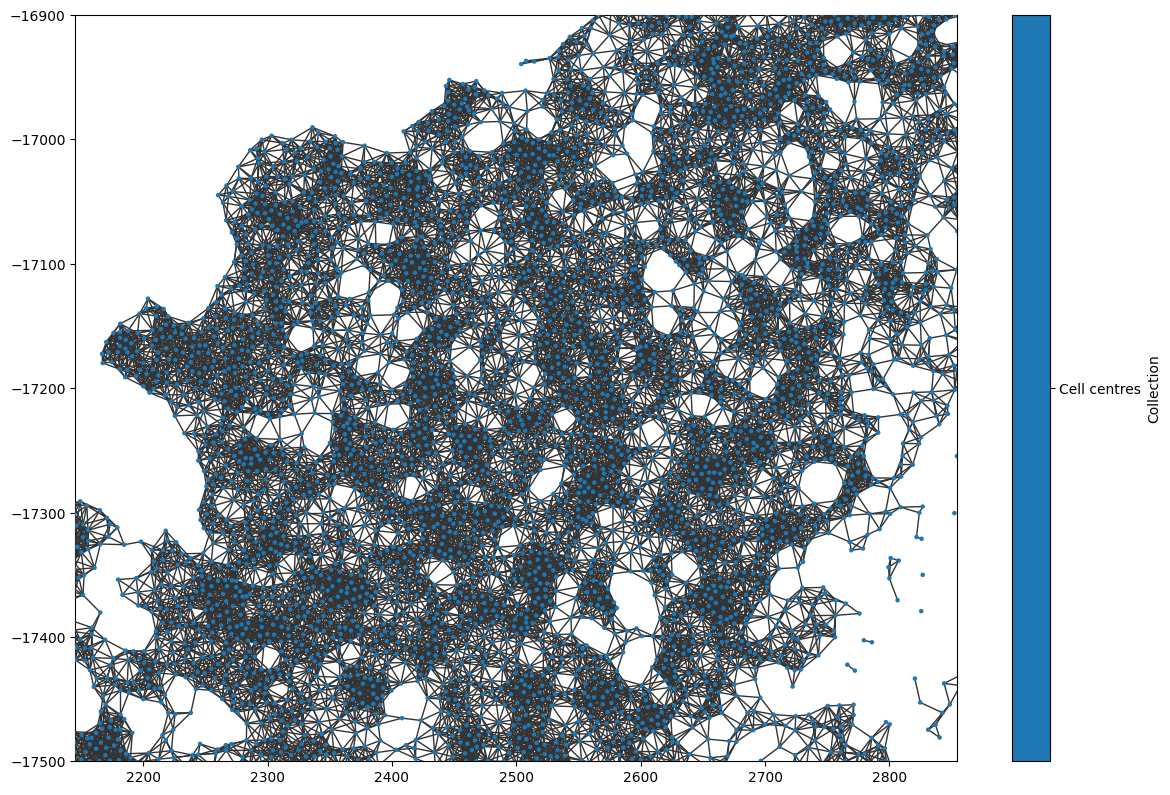

In [56]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 8), ncols=1, nrows=1)

ms.visualise.visualise_network(
    domain,
    network_name='proximity_boundary_20um',
    ax=ax,
    edge_cmap='viridis',
    edge_vmin=0,
    edge_vmax=50,
    add_cbar=False,
    visualise_kwargs=dict(objects_to_plot=('collection', 'Cell centroids'), marker_size=5)
)

x_centre = 2500
y_centre = -17200
x_side = 300
y_side = 300

ax.set_xlim(x_centre - x_side, x_centre + x_side)
ax.set_ylim(y_centre - y_side, y_centre + y_side)

(-17500.0, -16900.0)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


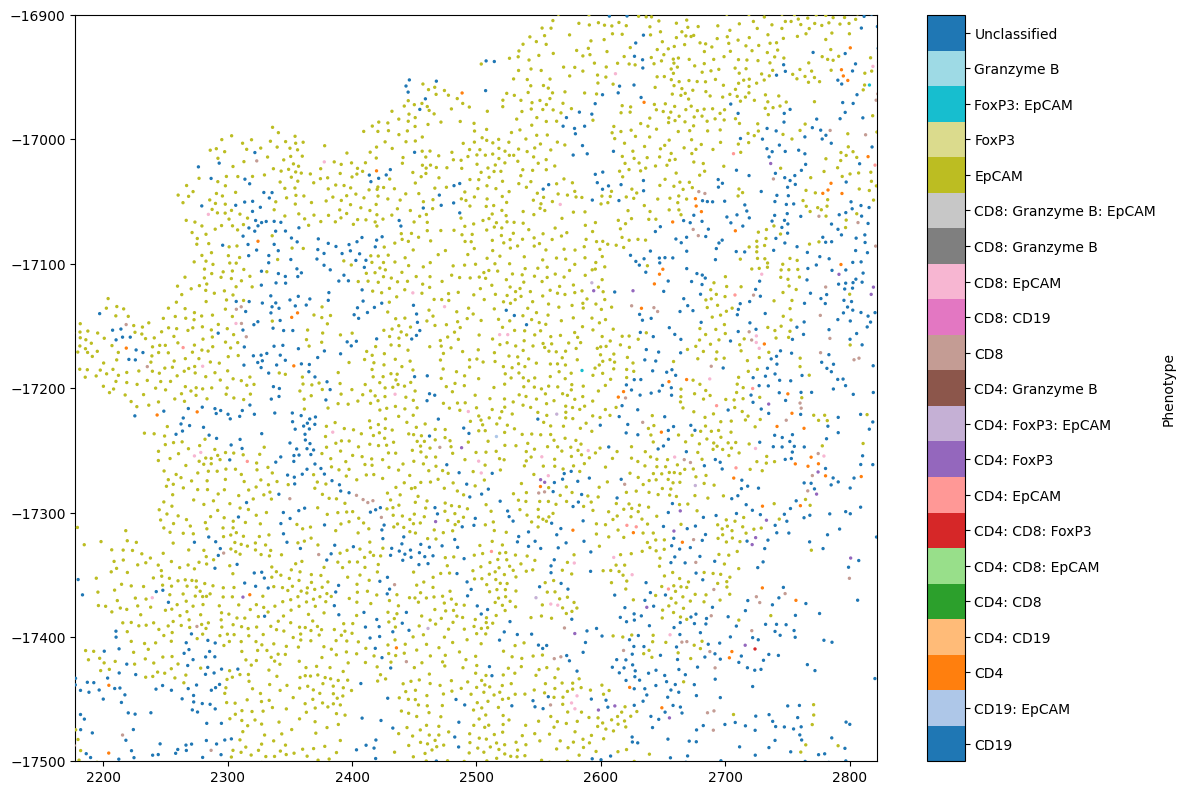

In [50]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 8), ncols=1, nrows=1)


ms.visualise.visualise(domain,
                       color_by='Phenotype',
                       show_boundary=True,
                       marker_size=2,
                       ax=ax)

x_centre = 2500
y_centre = -17200
x_side = 300
y_side = 300

ax.set_xlim(x_centre - x_side, x_centre + x_side)
ax.set_ylim(y_centre - y_side, y_centre + y_side)

## Distances between cells

In [64]:
paths = [r"Z:\Miki MuSpAn\AT3_EpCAM_output\CD4-pairs", r"Z:\Miki MuSpAn\AT3_EpCAM_output\CD8-pairs", r"Z:\Miki MuSpAn\AT3_EpCAM_output\GranzymeB-pairs"]

path_csvs = []

for path in paths:
    cur_files = [f for f in os.listdir(path) if f.endswith(".csv")]
    
    path_csvs.append(cur_files)

n_files = len(cur_files)

In [97]:
for i in range(n_files):
    name = path_csvs[0][i]
    df0 = pd.read_csv(os.path.join(paths[0], path_csvs[0][i]))
    df1 = pd.read_csv(os.path.join(paths[1], path_csvs[1][i]))
    df2 = pd.read_csv(os.path.join(paths[2], path_csvs[2][i]))

    common_columns = list(df0.columns)[:7]
    columns0 = list(df0.columns)[7:-1:2]
    columns1 = list(df1.columns)[7:-1:2]
    columns2 = list(df2.columns)[7:-1:2]

    new_df = df0[common_columns]
    new_df[columns0] = df0[columns0]
    new_df[columns1] = df1[columns1]
    new_df[columns2] = df2[columns2]

    new_df.to_csv(os.path.join(r"Z:\Miki MuSpAn\AT3_EpCAM_output\distances", name.replace(".csv", "_raw-distances.csv")))

C:\Users\ewestlund\AppData\Local\Temp\ipykernel_944\3960276083.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df[columns0] = df0[columns0]
C:\Users\ewestlund\AppData\Local\Temp\ipykernel_944\3960276083.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df[columns0] = df0[columns0]
C:\Users\ewestlund\AppData\Local\Temp\ipykernel_944\3960276083.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

In [96]:
new_df

,object_id,x,y,object_type,Raw Classification,Phenotype,Neighbourhood_ID_KNN_5,CD4_to_EpCAM,CD4_to_CD4: FoxP3,CD8_to_CD4,CD8_to_CD4: FoxP3,CD8_to_EpCAM,Granzyme B_to_EpCAM
0,0,2246.6,-26732.6,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2256.9,-26757.5,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2259.1,-26766.4,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2191.0,-26773.4,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2292.1,-26776.2,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
34739,34739,3330.9,-29826.8,point,Unclassified,Unclassified,4,NaN,NaN,NaN,NaN,NaN,NaN
34740,34740,3274.4,-29829.4,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
34741,34741,3372.6,-29829.9,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN
34742,34742,3385.8,-29842.6,point,Unclassified,Unclassified,1,NaN,NaN,NaN,NaN,NaN,NaN


## Proximity

In [ ]:
import numpy as np
import pandas as pd
import os

label_df = pd.read_csv(r"Z:\Miki MuSpAn\Proximity.csv")

label_order = label_df["Phenotype"].tolist()

path = r"Z:\Miki MuSpAn\AT3_EpCAM_output\proximity\domain_arrays"
files = [f for f in os.listdir(path) if f.endswith(".npy")]

parents = {}

for file in files:
    parent_name = file.split("_")[2].replace(".csv", "")
    array = np.load(os.path.join(path, file))

    parents[parent_name] = array
    #cur_df = pd.DataFrame(array, index=label_order, columns=label_order)

    #cur_df.to_csv(os.path.join(r"Z:\Miki MuSpAn\AT3_EpCAM_output\proximity\individual_csv", file.replace(".csv_array.npy", "_proximity.csv")))


In [59]:
metadata = pd.read_csv(r"Z:\Miki MuSpAn\metadata.csv")

smaller_data = metadata.loc[metadata["Timepoint"] == "Early"]

groups = list(smaller_data["Group"].unique())

samples_to_pool = []

for group in groups:
    cur_data = smaller_data.loc[smaller_data["Group"] == group]
    samples = list(cur_data["Parent"])
    samples_to_pool.append(samples)


groups, samples_to_pool

(['0 Gy', '5.2 Gy x5', '8 Gy x3', '2.67 Gy x5'],
 [['A1.3',
   'A1.2',
   'A1.5',
   'T1.3',
   'T1.1',
   'T1.2',
   'T1.4',
   'T1.5',
   'A13.2',
   'A13.3',
   'A13.4'],
  ['A3.1', 'A3.2', 'A3.5', 'T3.1', 'T3.2', 'T3.3', 'T3.4', 'T3.5'],
  ['A4.1', 'A4.3', 'A4.2', 'A4.5', 'T4.1', 'T4.2', 'T4.3', 'T4.5', 'T4.4'],
  ['T2.1', 'T2.2', 'T2.3', 'T2.4', 'T2.5', 'A2.4', 'A2.1', 'A2.2']])

## pool samples...

In [42]:
def pool_samples(parents, samples_to_pool):
    pooled = []

    for s in samples_to_pool:
        if s in parents.keys():
            pooled.append(parents[s])

    return np.sum(pooled, axis=0)

def remove_contacts_with_self(array):
    new_array = np.copy(array)
    for i in range(np.shape(array)[0]):
        new_array[i,i] = 0

    return new_array

def normalise_array(array):
    new_array = np.copy(array)
    total_contacts = np.sum(new_array, axis=1, keepdims=True)
    new_array = new_array/total_contacts

    return new_array


In [60]:
for i in range(len(samples_to_pool)):
    pool = samples_to_pool[i]
    group = groups[i]

    total_with_itself = pool_samples(parents, pool)
    total_without_itself = remove_contacts_with_self(total_with_itself)

    norm_with_itself = normalise_array(total_with_itself)
    norm_without_itself = normalise_array(total_without_itself)

    cur_df = pd.DataFrame(norm_with_itself, index=label_order, columns=label_order)

    cur_df.to_csv(os.path.join(r"Z:\Miki MuSpAn\AT3_EpCAM_output\contacts_plot", f"pooled_AT3_Early_{group}.csv"))



C:\Users\ewestlund\AppData\Local\Temp\ipykernel_944\270191383.py:20: RuntimeWarning: invalid value encountered in divide
  new_array = new_array/total_contacts


In [ ]:
i = 0
pool = samples_to_pool[i]
print(samples_to_pool[i], groups[i])

total_with_itself = pool_samples(parents, pool)
total_without_itself = remove_contacts_with_self(total_with_itself)

norm_with_itself = normalise_array(total_with_itself)
norm_without_itself = normalise_array(total_without_itself)

## ... or read in from script

In [ ]:
# Get Clusteres of Interest
norm_without_path = r"Z:\Miki MuSpAn\AT3_EpCAM_output\proximity\combined_arrays\norm_array_without_itself.npy"
total_with_path = r"Z:\Miki MuSpAn\AT3_EpCAM_output\proximity\combined_arrays\total_array.npy"

df = pd.read_csv(r"Z:\Miki MuSpAn\Proximity.csv")
clusters_of_interest = df["Phenotype"].tolist()

total_array = np.load(total_with_path)
norm_array = np.load(norm_without_path)

# Plot!

C:\Users\ewestlund\AppData\Local\Temp\ipykernel_944\3031835607.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(clusters_of_interest, rotation=45, ha='right')


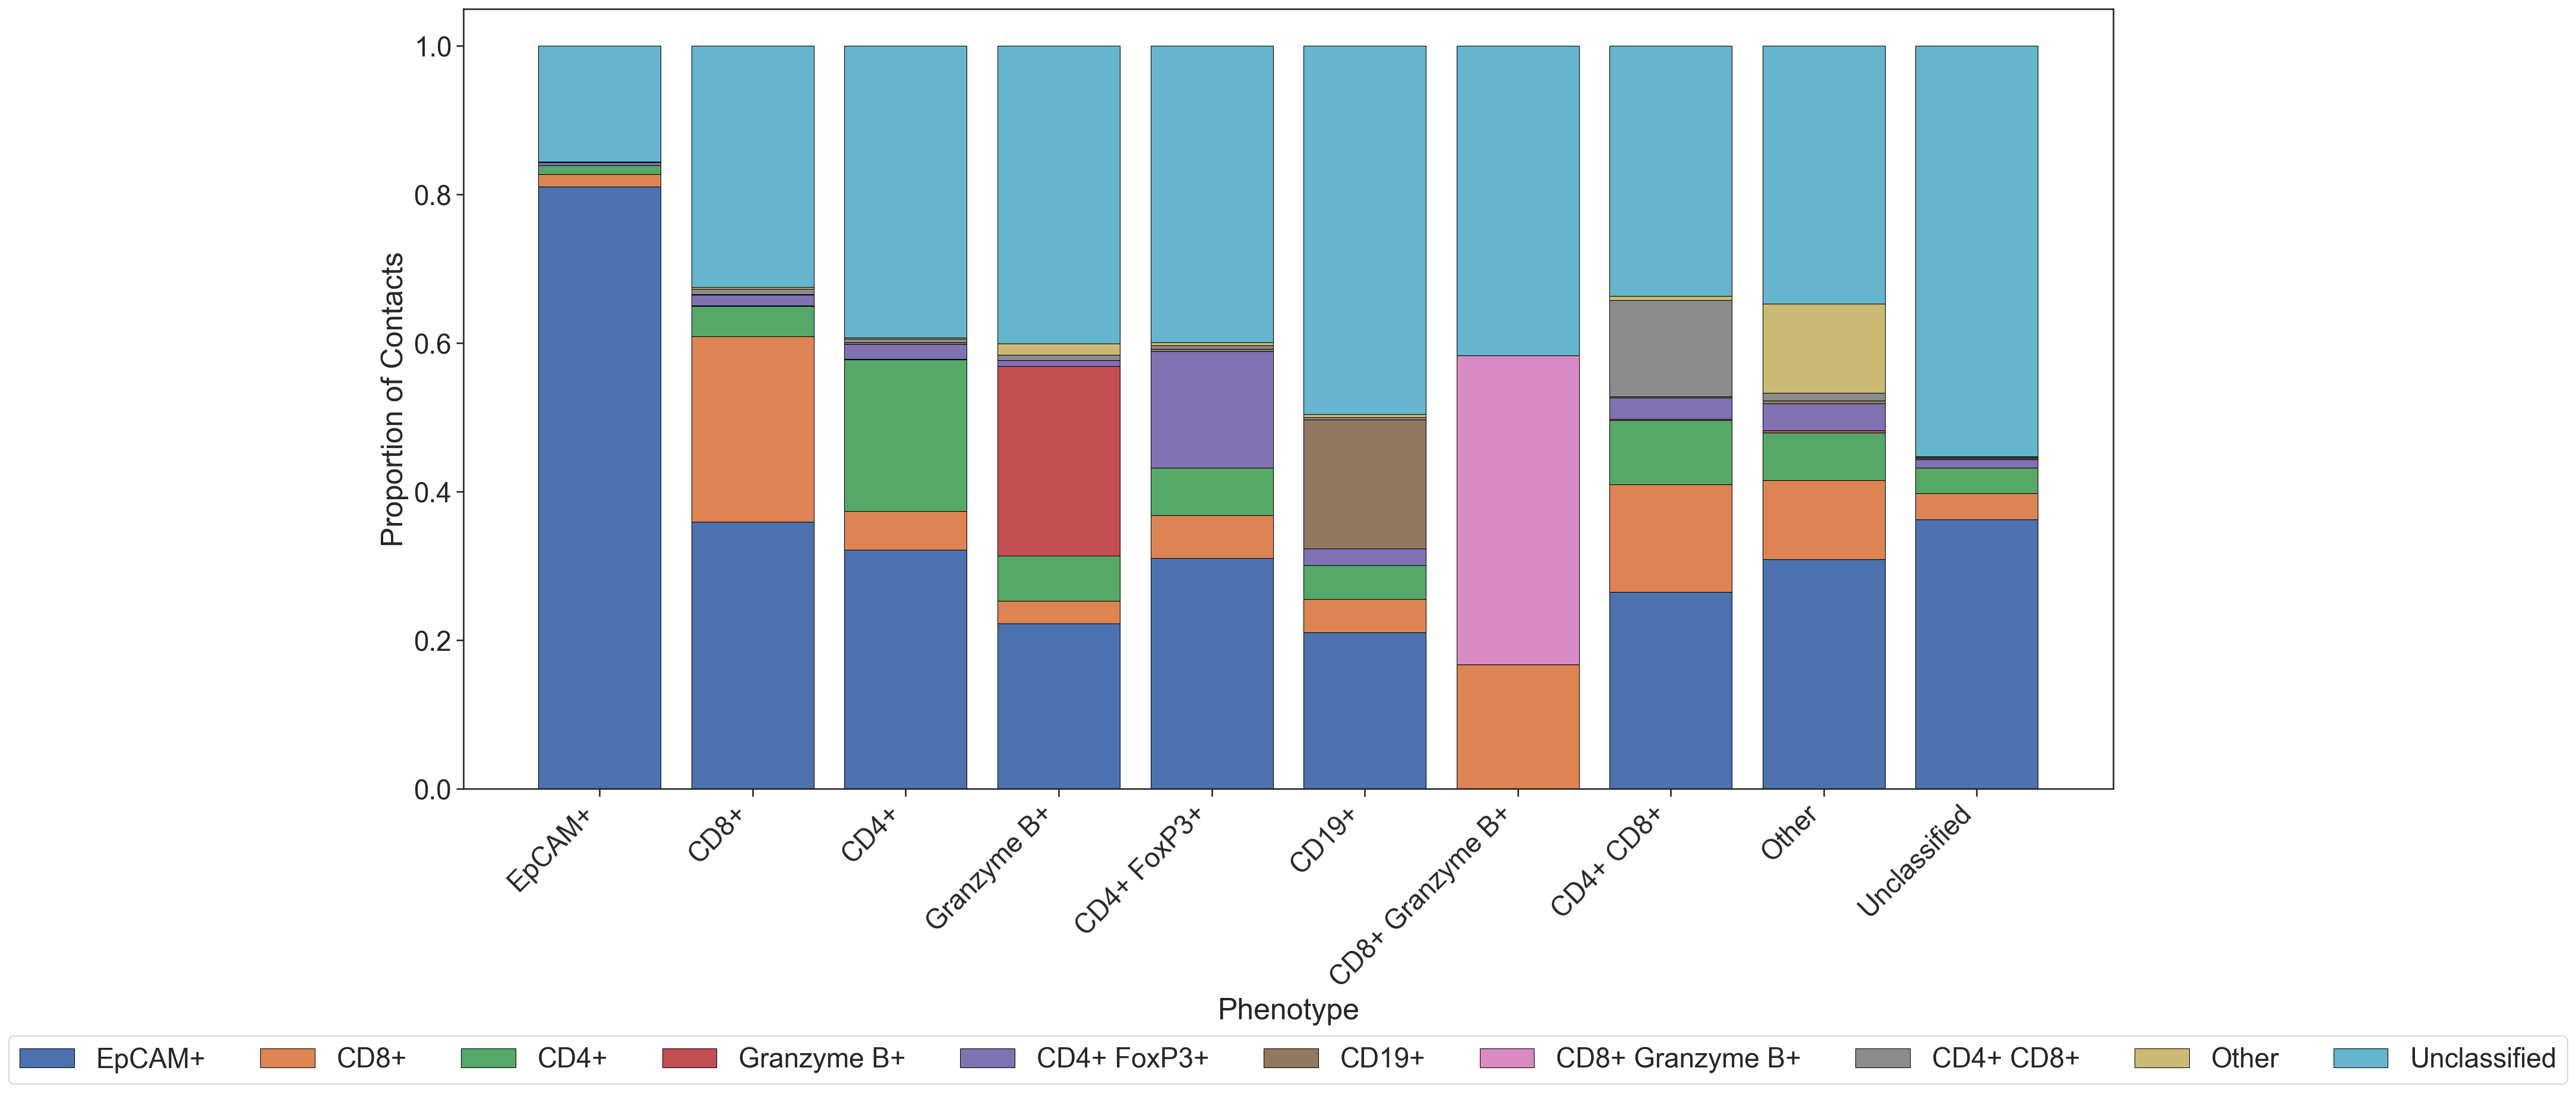

In [53]:
norm_array = norm_with_itself
clusters_of_interest = label_order

# Set the theme for seaborn plots
sns.set_theme(style='white', font_scale=2)
sns.set_style('ticks')

# Create a figure with two subplots

fig2, ax2 = plt.subplots(figsize=(20, 10))
fig2.tight_layout()


# Plot the stacked bar plot for each cluster
for i, cluster in enumerate(clusters_of_interest):
    ax2.bar(clusters_of_interest, norm_array[:, i], 
            label= cluster, bottom=np.sum(norm_array[:, :i], axis=1), 
            #color=phenotype_colors[cluster],
            edgecolor = "black",
            linewidth = 0.5)

# Set x-axis and y-axis labels for the stacked bar plot
ax2.set_xlabel('Phenotype')
ax2.set_ylabel('Proportion of Contacts')

# Set x-axis labels for the stacked bar plot
ax2.set_xticklabels(clusters_of_interest, rotation=45, ha='right')

# Add legend to the stacked bar plot
ax2.legend(bbox_to_anchor=(0.5, -0.30), loc='upper center', ncol=13)

# Show the plot
plt.show()